# Knockouts, the cell cycle and heterogeneity

The project goal has two halves: read out cell-cycle state from morphology, then **normalise or regress the cell cycle out of
perturbation profiles and test whether that reduces the apparent heterogeneity of perturbed populations**. Notebooks 16 and 17
built and aligned the cell-cycle readout. This notebook uses it on the knockouts:

1. **Cells of perturbations likely to affect the cycle** (building on Brian's CDK7 / CCNB1 figures): which knockouts shift the
   cell-cycle distribution, compared fairly against non-targeting controls, and checked against measured 4i markers.
2. **The whole library** (1,000 OPS0077 knockouts, 591,136 cells): cycle shifts, and heterogeneity before and after regressing the cycle out.
3. **Three questions about cycle normalisation.** Does it (1) reduce field and well heterogeneity, (2) find perturbations that
   change the cell-cycle distribution, and (3) separate those from perturbations that change the cells themselves?
4. **A cell-cycle representation of the CROP-seq knockouts**, and how it maps to phase-contrast morphology.

> **"phase" is used for two things.** *Cell-cycle phase* (G1/S/G2/M, or the angle `cc_phase`) is what we read out.
> *Phase contrast* (label-free) is the imaging modality. Phase-contrast **morphology** is always the predictor here.

**Model.** Phase-contrast OrganelleProfiler features -> PCA-100 -> ridge to the sine and cosine of the 4i `cc_phase` (circular
regression), and logistic regression to the DNA-content class (4N vs 2N, measured DAPI). Both are trained on NTC cells only, with folds
grouped by imaging tile. Out of fold, the angle is predicted with a median error of 30 degrees and 4N with AUC 0.92.

In [1]:
import os, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 180); pd.set_option('display.max_columns', 30)

def find(n):
    for r in ['reports/ko_cell_cycle', 'ko18_reports', '.']:
        if os.path.exists(f'{r}/{n}'): return f'{r}/{n}'
    raise FileNotFoundError(n)

## 1. Building on Brian's figures: 60 likely-arrest knockouts and 60 random controls

**What.** For the 60 knockouts on the likely-arrest list, plus 60 random library genes as controls (other library genes with at
least 300 cells; the library is enriched for essential genes, so these are not neutral), we predict every cell's cycle position
from phase contrast and compare each knockout's distribution with NTC.

**How (and why it differs from a direct comparison).**
* **Same pipeline on both sides.** Knockout cells are never in training, so NTC predictions must be out of fold too.
* **All NTC cells as the reference.** About a third of NTC cells (16,556 of 52,189) have no measured clock (no reliable single
  nucleus), and the knockout cells were never filtered that way. Using only clock-labelled NTC cells as the reference biases every
  comparison (more late-cycle cells), so the reference is all NTC cells.
* **A null with the right noise.** NTC guides pooled to the knockout's cell count, then the same comparison, 400 draws, BH FDR.

**Result.** 8 of 120 knockouts shift the predicted cycle distribution (FDR 5%; 7 arrest genes, 1 control).
* **CDK7 and CCNB1 are not among them.** Their late-cycle (0.75 to 1) shifts are +3.2 and +3.8 percentage points (q 0.12 and 0.13),
  far smaller than the +10.8 and +7.3 in Brian's panel.
* **NTC composition.** Brian's NTC composition matches the *predicted* NTC composition, not the measured 4i one.
* **The sharp vs smooth curves in his panel B** are most likely a density-smoothing effect: knockouts have a few hundred cells and
  NTC tens of thousands, and the smoothing depends on cell count.

**Validation.** Across the 120 knockouts the predicted shifts track measured pRb on the same cells (last quarter of `cc_phase`
rho -0.40, second quarter +0.39). For the three genes with measured DNA, the predicted late-cycle gain matches the measured 4N gain for
CCNB1 (+4.3 measured vs +4.2 / +3.8 predicted) and MCM3 (+4.2 vs +2.7 / +2.9).

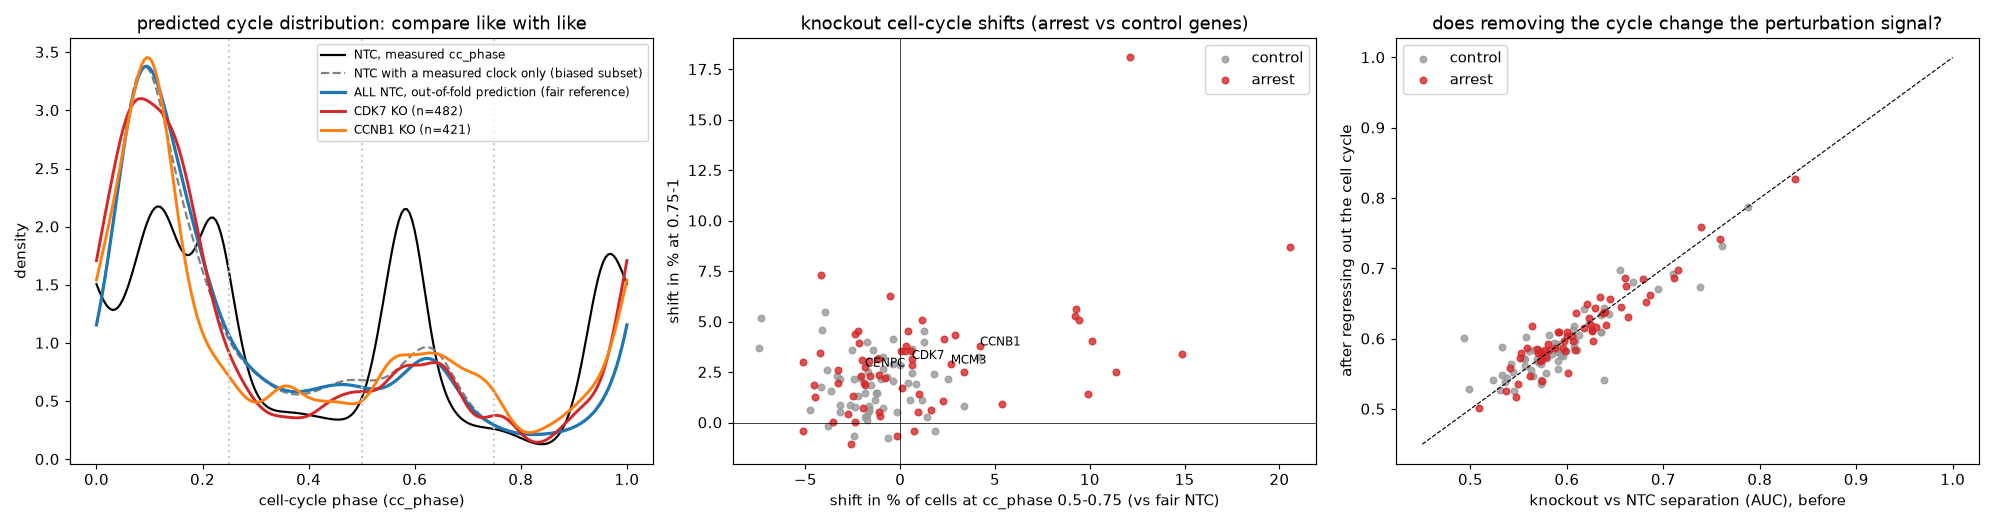

significant at FDR 5%: 8 of 120


,gene,cls,n,d_0-0.25,d_0.25-0.5,d_0.5-0.75,d_0.75-1,min_q,measured_pRb_shift_log2
81,POLE2,arrest,397,-11.71,-2.80,9.20,5.30,0.038,-0.109
80,POLE,arrest,441,-11.24,-3.27,9.41,5.10,0.038,-0.279
79,POLA2,arrest,305,-14.40,-3.86,14.84,3.42,0.038,-0.106
78,POLA1,arrest,530,-14.98,1.09,11.37,2.51,0.038,-0.056
6,AURKB,arrest,424,-12.15,-2.73,9.25,5.63,0.038,-0.440
72,NOL6,control,566,5.35,-3.22,-7.33,5.20,0.038,-0.457
18,CDC45,arrest,364,-21.40,-7.86,20.55,8.71,0.038,-0.413
69,MCM7,arrest,622,-11.08,-0.25,9.90,1.43,0.038,-0.120
84,PPP2CA,arrest,560,-1.99,-1.11,-4.20,7.31,0.054,-0.332
102,SMARCC1,arrest,767,-3.12,-1.00,0.57,3.55,0.054,-0.061


In [2]:
display(Image(filename=find('ko_cycle_overview.png')))
r = pd.read_csv(find('ko_predicted_cycle_composition.csv'))
q = [c for c in r if c.startswith('q_')]
print('significant at FDR 5%:', int((r[q].min(1) < .05).sum()), 'of', len(r))
r.assign(min_q=r[q].min(1)).sort_values('min_q').head(12)[['gene', 'cls', 'n'] + [c for c in r if c.startswith('d_') and 'labelled' not in c] + ['min_q', 'measured_pRb_shift_log2']].round(3)

In [3]:
print(open(find('ko_cycle_heterogeneity_log.txt')).read().split('variance of NTC')[0][-1600:])
pd.read_csv(find('ko3_measured_vs_predicted.csv'))

.126)] | vs labelled-only NTC [np.float64(-2.89), np.float64(-3.5), np.float64(2.53), np.float64(3.86)]
  MCM3   n= 729 shift vs fair NTC [np.float64(-8.15), np.float64(2.56), np.float64(2.67), np.float64(2.92)] q [np.float64(0.0667), np.float64(0.768), np.float64(0.4175), np.float64(0.0818)] | vs labelled-only NTC [np.float64(-6.6), np.float64(2.64), np.float64(1.0), np.float64(2.95)]
  CENPC  n= 453 shift vs fair NTC [np.float64(0.95), np.float64(-1.86), np.float64(-1.86), np.float64(2.77)] q [np.float64(0.9516), np.float64(0.8649), np.float64(0.7601), np.float64(0.2533)] | vs labelled-only NTC [np.float64(2.5), np.float64(-1.77), np.float64(-3.53), np.float64(2.8)]
mean shift per quarter (signed, all 120 genes), vs labelled-only NTC: [ 0.49 -1.12 -1.83  2.46] | vs ALL NTC (fair): [-1.06 -1.21 -0.16  2.43]
  predicted % in quarter 0-0.25 vs measured pRb shift across 120 knockouts: rho -0.18 (p=0.053)
  predicted % in quarter 0.25-0.5 vs measured pRb shift across 120 knockouts: rho +0

,gene,n,measured_4N_pct_shift,predicted_shift_0p5_0p75,predicted_shift_0p75_1
0,CCNB1,349,4.3,4.21,3.82
1,CENPC,374,-1.3,-1.86,2.77
2,MCM3,630,4.2,2.67,2.92


## 2. The whole library: which knockouts change the cell-cycle distribution

**What.** The same model applied to all 1,000 OPS0077 knockouts (591,136 cells).

**How.** For each knockout, the predicted cycle distribution is compared with NTC (total variation over 12 cycle bins), together
with its predicted change in % 4N cells. The null is NTC guides pooled to the knockout's cell count (2,000 draws), with BH FDR over
1,000 knockouts.

**Result.**
* **81 knockouts change the predicted cycle distribution**, and the direction makes biological sense:
  * **DNA replication and mitosis/cytokinesis genes gain 4N cells**, for example CDC45 (+10.5 points), MTBP (+14.3), KIF23 (+11.8),
    POLA1/POLA2/POLE/POLE2, MCM7, RRM1 and AURKB.
  * **Ribosome, translation, RNA polymerase I and chaperonin genes lose 4N cells**, for example POLR1B (-8.5), RPL27A, RPS28, TCP1,
    CCT3/6A/7 and EIF2S1. These cells accumulate before S phase, as expected for nucleolar and translational stress.
* **Validation:** the predicted change in % 4N agrees with measured pRb on the same knockout cells across all 1,000 knockouts (rho +0.37).

In [4]:
R = pd.read_csv(find('ko_library_cycle.csv'))
cols = ['gene', 'n', 'cycle_TV', 'q_cycle', 'd_pct_4N_pred', 'measured_pRb_shift_log2', 'within_vs_null_median', 'q_within', 'cycle_share_of_shift', 'auc_before', 'auc_after']
print('knockouts with a significant cycle-distribution change:', int((R.q_cycle < .05).sum()))
R[R.q_cycle < .05].sort_values('cycle_TV', ascending=False)[cols].head(25).round(3)

knockouts with a significant cycle-distribution change: 81


,gene,n,cycle_TV,q_cycle,d_pct_4N_pred,measured_pRb_shift_log2,within_vs_null_median,q_within,cycle_share_of_shift,auc_before,auc_after
762,RRM1,153,0.302,0.011,5.320,-0.285,5.806,0.001,0.127,0.751,0.726
617,POLR1B,321,0.293,0.011,-8.510,-0.507,4.780,0.001,-0.040,0.867,0.846
128,CDC45,364,0.293,0.011,10.502,-0.413,7.998,0.001,0.127,0.836,0.801
732,RPL26,182,0.264,0.011,2.391,-0.527,6.136,0.001,0.038,0.851,0.815
745,RPS10,151,0.260,0.011,-4.497,-0.502,4.389,0.001,-0.019,0.796,0.753
733,RPL27A,158,0.257,0.011,-6.041,-0.513,3.851,0.001,0.013,0.717,0.679
523,MTBP,276,0.256,0.011,14.342,-0.234,5.582,0.001,0.174,0.705,0.685
766,RSL24D1,219,0.255,0.011,-0.839,-0.500,4.683,0.001,0.014,0.749,0.732
877,TCP1,280,0.241,0.011,-6.229,-0.501,3.034,0.001,0.031,0.757,0.717
439,KIF23,235,0.239,0.011,11.784,-0.400,4.344,0.001,0.175,0.641,0.667


## 3. Regressing the cycle out: does heterogeneity go down?

**What.** The project hypothesis: removing the cell-cycle component from perturbation profiles should reduce the apparent heterogeneity
of perturbed populations.

**How.**
* **What is removed.** From every phase-contrast dimension (PCA-100) we remove the part explained by the predicted cycle (sine and
  cosine, first and second harmonics). The coefficients are fit on NTC cells using out-of-fold predictions.
* **Heterogeneity** is measured two ways: the spread of each knockout population (mean distance to its centroid), and how separable
  it is from NTC (held-out logistic AUC).
* **Controls.** A shuffled cycle is the control. A knockout counts as "separating" when its AUC is above the 95th percentile of NTC
  guide pools of the same size.

**Result: heterogeneity barely changes.**
* **Spread** falls by a median of **3.0%** (shuffled cycle: +0.004%), the same for arrest and non-arrest knockouts.
* **Separation from NTC** is essentially unchanged: median AUC change -0.001. 595 knockouts separate from NTC before and 610 after,
  so removing the cycle neither erases perturbation signal nor sharpens it overall.
* **Per-knockout AUC changes are noise; do not read them gene by gene.** Two independent runs on the same 120 knockouts reproduce
  the AUC itself (r 0.91), but not the before-to-after change (r 0.02; the run-to-run difference, SD 0.036, is as large as the
  changes). Which knockouts' phenotypes are "mostly cell cycle" is answered by the deterministic decomposition in section 4:
  the cycle shift explains at most about a quarter of any knockout's morphology change.

**Why so little:** the cell cycle is a *predictable* but *low-variance* direction of phase morphology. Even the **measured** cycle
explains only 2.9% (harmonics 1 to 2) to 5.7% (all four 4i readouts) of NTC phase-morphology variance, while the first principal
component alone explains 12.3%.

percent of NTC phase-morphology variance (PCA-100) explained by:
  measured cc_phase, harmonics 1-2                 2.9%
  measured cc_phase, harmonics 1-4                 3.5%
  measured DNA content (cubic)                     2.4%
  measured DNA+pRb+p21+phos (linear+squares)       5.7%
  shuffled cc_phase                                0.0%
for scale: PC1 alone explains 12.3 % of the PCA-100 variance



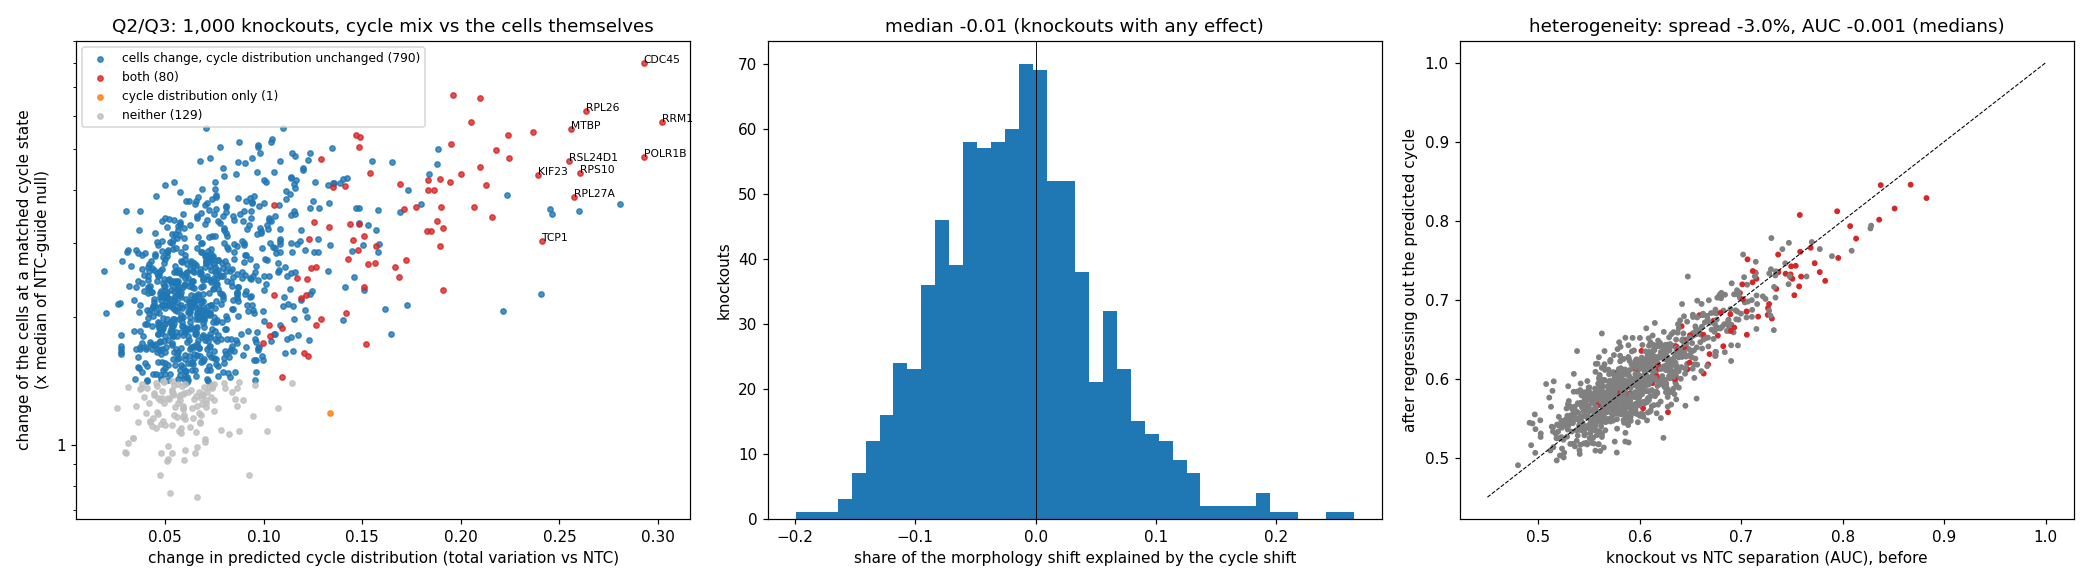

,spread_change_pct,spread_change_shuffled_pct,auc_before,auc_after,auc_change
count,1000.000,1000.000,1000.000,1000.000,1000.000
mean,-3.064,0.004,0.606,0.604,-0.001
std,0.425,0.007,0.060,0.057,0.027
min,-5.479,-0.025,0.480,0.490,-0.098
25%,-3.266,-0.000,0.565,0.565,-0.019
50%,-3.046,0.004,0.593,0.594,-0.001
75%,-2.801,0.009,0.633,0.634,0.016
max,-1.772,0.033,0.883,0.846,0.097


In [5]:
print(open(find('cycle_variance_bound.txt')).read())
display(Image(filename=find('library_cycle_decomposition.png')))
R[['spread_change_pct', 'spread_change_shuffled_pct', 'auc_before', 'auc_after', 'auc_change']].describe().round(3)

In [6]:
# reproducibility of per-knockout AUC values and AUC changes: the 120-gene run (section 1) vs the library run, same knockouts
a = pd.read_csv(find('ko_heterogeneity_before_after.csv')); m = a.merge(R, on='gene', suffixes=('_120', '_library'))
pd.Series({'knockouts in both runs': len(m),
           'AUC before, r between runs': m.auc_before_120.corr(m.auc_before_library),
           'AUC after, r between runs': m.auc_after_120.corr(m.auc_after_library),
           'AUC change, r between runs': m.auc_change_120.corr(m.auc_change_library),
           'SD of the run-to-run difference in AUC change': (m.auc_change_120 - m.auc_change_library).std(),
           'SD of AUC change across the library': R.auc_change.std()}).round(3)

knockouts in both runs                           120.000
AUC before, r between runs                         0.912
AUC after, r between runs                          0.890
AUC change, r between runs                         0.018
SD of the run-to-run difference in AUC change      0.036
SD of AUC change across the library                0.027
dtype: float64

## 4. Three questions about normalising by the cell cycle

Does normalising or weighting cell-cycle scores (1) reduce field and well heterogeneity, (2) find perturbations that change the
cell-population distribution, or (3) separate those from perturbations that only change the cells?

**Two normalisations:**
* **regress**: remove the cycle-explained part of every morphology dimension;
* **reweight**: weight reference cells so that their cycle distribution matches the target.

**Two datasets:**
* **OPS0077**: phase contrast; cycle predicted from morphology, with the measured 4i clock as a check.
* **Element**: imaging features; cycle **measured from RNA**, so it cannot be circular with morphology. It includes a TNFa stimulus and 5 knockouts.

### Q1. Field and well heterogeneity: not reduced

**How.** For control cells we measure the share of morphology variance that lies **between wells or between fields** (tiles with at
least 30 cells), minus what random sampling alone gives (permuted labels).

**Result.**
* **With a measured clock, normalisation changes almost nothing:**
  * Element wells: 1.67% before, 1.72% after regressing, 1.67% after reweighting.
  * Element fields: 7.2%, 7.4%, 7.2%.
  * OPS0077 fields: 7.9%, 7.8%, 7.9%.
* **The apparent reduction with the predicted cycle (OPS0077 fields 12.4% to 10.7%) is circular.** Wells do not differ in measured
  cycle composition beyond chance (spread of the late-cycle share across wells 0.34% vs 0.32% if random), but they do in predicted
  composition (2.8% vs 0.2%). The predictor reads a technical well difference as "cycle".
* **Why:** fields do differ somewhat in measured cycle composition (local density), but that difference explains at most about 2% of the field effect.

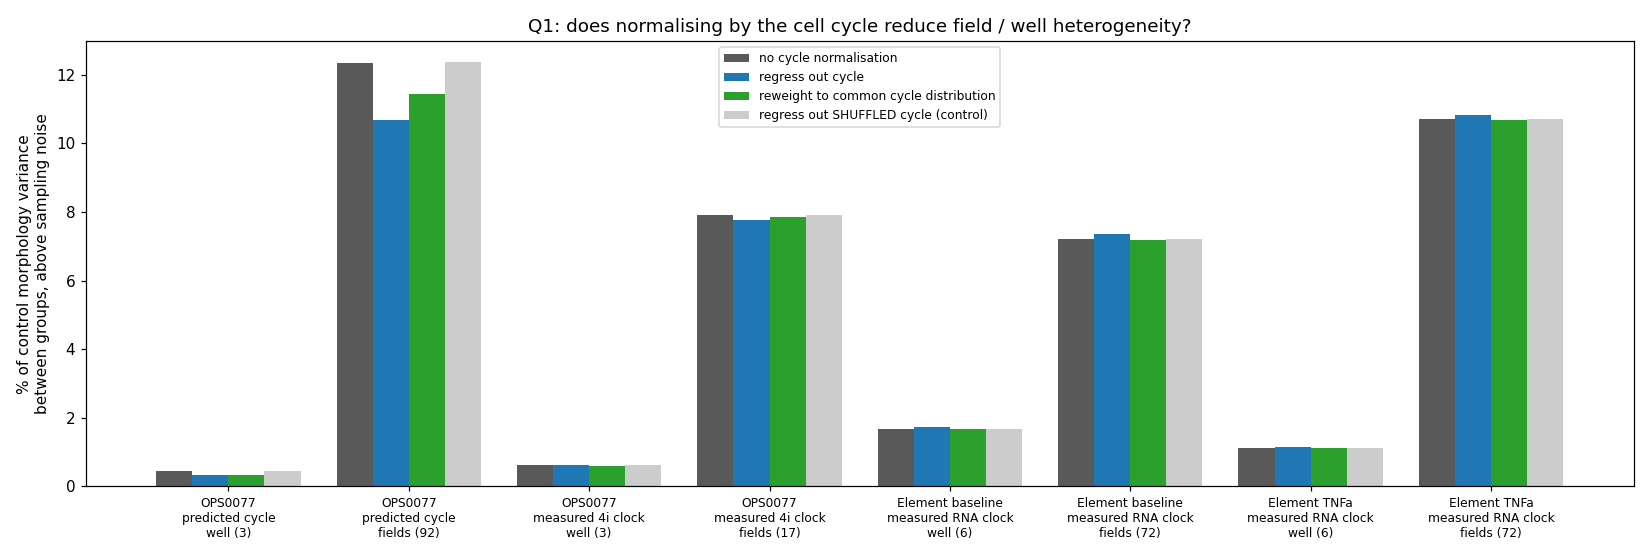

,dataset,grouping,n_groups,arm,between_share_pct,noise_floor_pct,excess_pct,sd_across_groups_of_late_cycle_share_pct,same_if_random_pct
0,"OPS0077 (predicted cycle, all NTC)",well,3,no cycle normalisation,0.448,0.004,0.444,2.76,0.21
1,"OPS0077 (predicted cycle, all NTC)",well,3,regress out cycle,0.332,0.004,0.328,2.76,0.21
2,"OPS0077 (predicted cycle, all NTC)",well,3,reweight to common cycle distribution,0.327,0.004,0.324,2.76,0.21
3,"OPS0077 (predicted cycle, all NTC)",well,3,regress out SHUFFLED cycle (control),0.448,0.004,0.445,2.76,0.21
4,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,no cycle normalisation,15.187,2.830,12.357,13.66,7.61
5,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,regress out cycle,13.529,2.835,10.694,13.66,7.61
6,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,reweight to common cycle distribution,14.737,3.286,11.451,13.66,7.61
7,"OPS0077 (predicted cycle, all NTC)","field (tile, >=30 cells)",92,regress out SHUFFLED cycle (control),15.185,2.818,12.368,13.66,7.61
8,"OPS0077 (MEASURED 4i clock, labelled NTC)",well,3,no cycle normalisation,0.641,0.006,0.635,0.34,0.32
9,"OPS0077 (MEASURED 4i clock, labelled NTC)",well,3,regress out cycle,0.639,0.005,0.634,0.34,0.32


In [7]:
display(Image(filename=find('q1_field_well_heterogeneity.png')))
pd.read_csv(find('q1_field_well_heterogeneity.csv'))

### Q2 and Q3. Cycle mix versus the cells themselves

**How.** Each perturbation's morphology shift (centroid vs control) is split exactly into two parts:
* **cycle-mix part**: the shift control cells would show if they had the perturbation's cycle distribution (reweighting);
* **matched-cycle part**: the remaining shift, at a matched cycle state.

Each part is tested against the same null as above (NTC guides pooled to n for OPS0077). For Element the null is halves of baseline
wells for TNFa, and single control guides for the knockouts.

**Result (OPS0077, 1,000 knockouts).**

| class | knockouts |
|---|---|
| cells change, cycle distribution unchanged | 790 |
| both | 80 |
| cycle distribution only | 1 (HSPA14) |
| neither | 129 |

**Even among knockouts that shift the cycle, the cycle shift explains little of the morphology change** (median share 0.01, 10th to
90th percentile -0.11 to +0.16).

**Result (Element, measured RNA clock).**
* **TNFa** shifts the cycle distribution slightly (TV 0.038 vs largest null 0.028) and moves morphology a lot (shift 17.8), but its
  cycle-mix part is 0.3% of that.
* **CTNNB1 and TGFBR2 knockouts** shift the cycle (CTNNB1 clearly), yet their cycle-mix part is under 2% of their morphology change.

**So:**
* **(2) yes**, cycle distribution changes can be found, best with a measured clock;
* **(3) yes**, the decomposition separates the two, and in both datasets perturbations that change morphology do so at a matched cycle state. None acts only by changing the cycle mix.

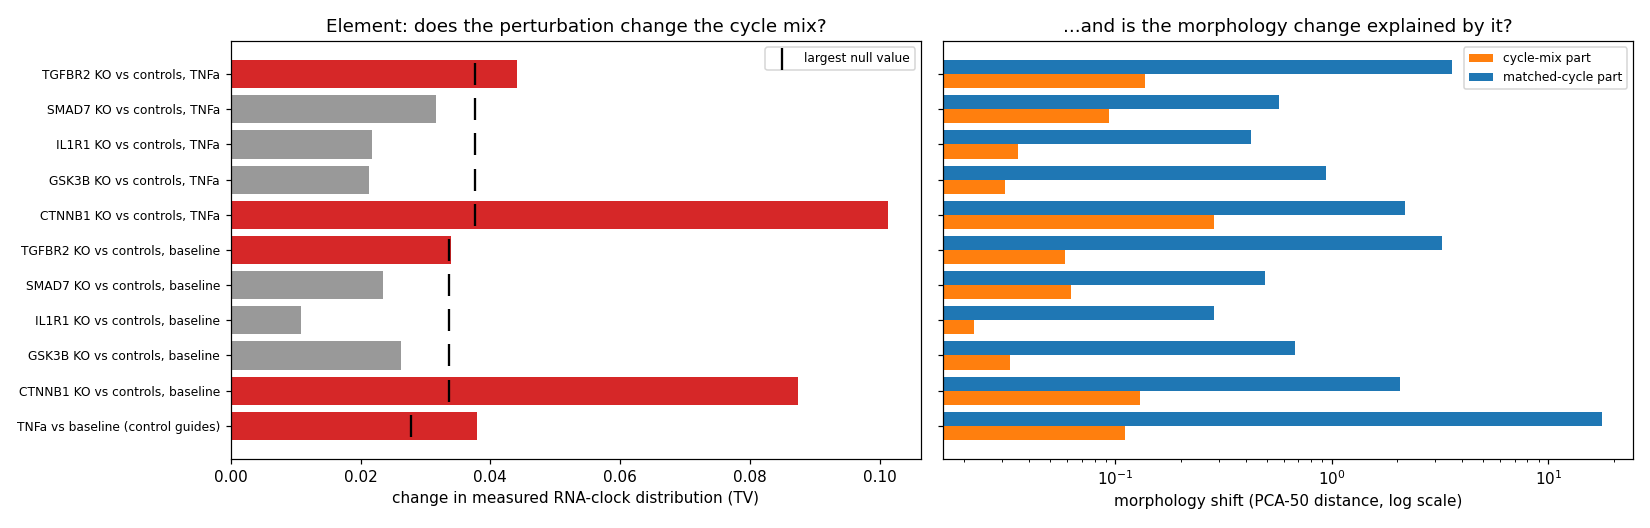

,cycle_TV,total_shift,cycle_part,within_cycle_part,cycle_share_of_shift,contrast,n,null,null_max_cycle_TV,null_max_within,cycle_beyond_null,within_beyond_null
0,0.038,17.752,0.111,17.701,0.003,TNFa vs baseline (control guides),47130,baseline wells split in halves,0.028,2.936,True,True
1,0.087,2.023,0.130,2.064,-0.018,"CTNNB1 KO vs controls, baseline",23290,single control guide vs other control guides,0.034,0.782,True,True
2,0.026,0.672,0.033,0.674,-0.002,"GSK3B KO vs controls, baseline",16792,single control guide vs other control guides,0.034,0.782,False,False
3,0.011,0.281,0.022,0.284,-0.008,"IL1R1 KO vs controls, baseline",7109,single control guide vs other control guides,0.034,0.782,False,False
4,0.023,0.529,0.062,0.489,0.079,"SMAD7 KO vs controls, baseline",5115,single control guide vs other control guides,0.034,0.782,False,False
5,0.034,3.270,0.058,3.240,0.010,"TGFBR2 KO vs controls, baseline",3577,single control guide vs other control guides,0.034,0.782,True,True
6,0.101,2.096,0.284,2.183,-0.033,"CTNNB1 KO vs controls, TNFa",22058,single control guide vs other control guides,0.038,0.598,True,True
7,0.021,0.915,0.031,0.937,-0.023,"GSK3B KO vs controls, TNFa",17160,single control guide vs other control guides,0.038,0.598,False,True
8,0.022,0.420,0.035,0.422,-0.001,"IL1R1 KO vs controls, TNFa",6618,single control guide vs other control guides,0.038,0.598,False,False
9,0.032,0.595,0.094,0.567,0.058,"SMAD7 KO vs controls, TNFa",5060,single control guide vs other control guides,0.038,0.598,False,False


In [8]:
display(Image(filename=find('element_cycle_decomposition.png')))
pd.read_csv(find('q23_element_decomposition.csv')).round(3)

## 5. A cell-cycle representation of the CROP-seq knockouts, mapped to phase contrast

**The data.** The Altair CROP-seq data are public only at knockout level: DESeq2 knockout-vs-control statistics for 1,000 knockouts
x 9,999 genes. There are no single cells, so the representation is per knockout. The CROP-seq cells are not the imaged cells; the
knockout is the link.

**How the representation is built.**
* **Cycling genes from single cells.** Element (A549, single-cell RNA with a measured RNA clock) gives the expression of every gene
  around the cycle. We keep 397 strongly cycling genes: peak-to-trough at least 0.8 log2, and the same profile in two halves of the
  wells (r at least 0.8).
* **Programmes.** Genes are grouped by where they peak: S, G2/M or G1, using Element's own phase calls and DNA content per clock bin.
* **Score per knockout.** The mean DESeq2 statistic over each programme (the knockout's own gene excluded), as a z-score against
  1,000 random gene sets matched for expression.
* **A composition deconvolution was also tried and is a documented negative.** It models the knockout as a re-weighting of cells
  along the control clock. It was not reproducible across halves of the genes (rho 0.05), and 0 of 997 knockouts passed its null.

**Result: the CROP-seq cycle signal is weak and mostly absent.**
* **Few knockouts move a programme.** 14 of 997 move any programme beyond |z| 4.
* **One standout.** SMARCD1 (S z -12, G2/M z -18) stands out. In phase contrast it does not shift the predicted cycle distribution (q 0.30).
* **Reliability is weak across all knockouts** (G2/M programme split-half 0.23), though high among the few strong ones (G1: 0.95).
* **The canonical arrest genes are flat in CROP-seq RNA** (CCNB1, CDK7, AURKB, CDC45, POLA1: all |z| < 3), although several are
  strong in imaging.

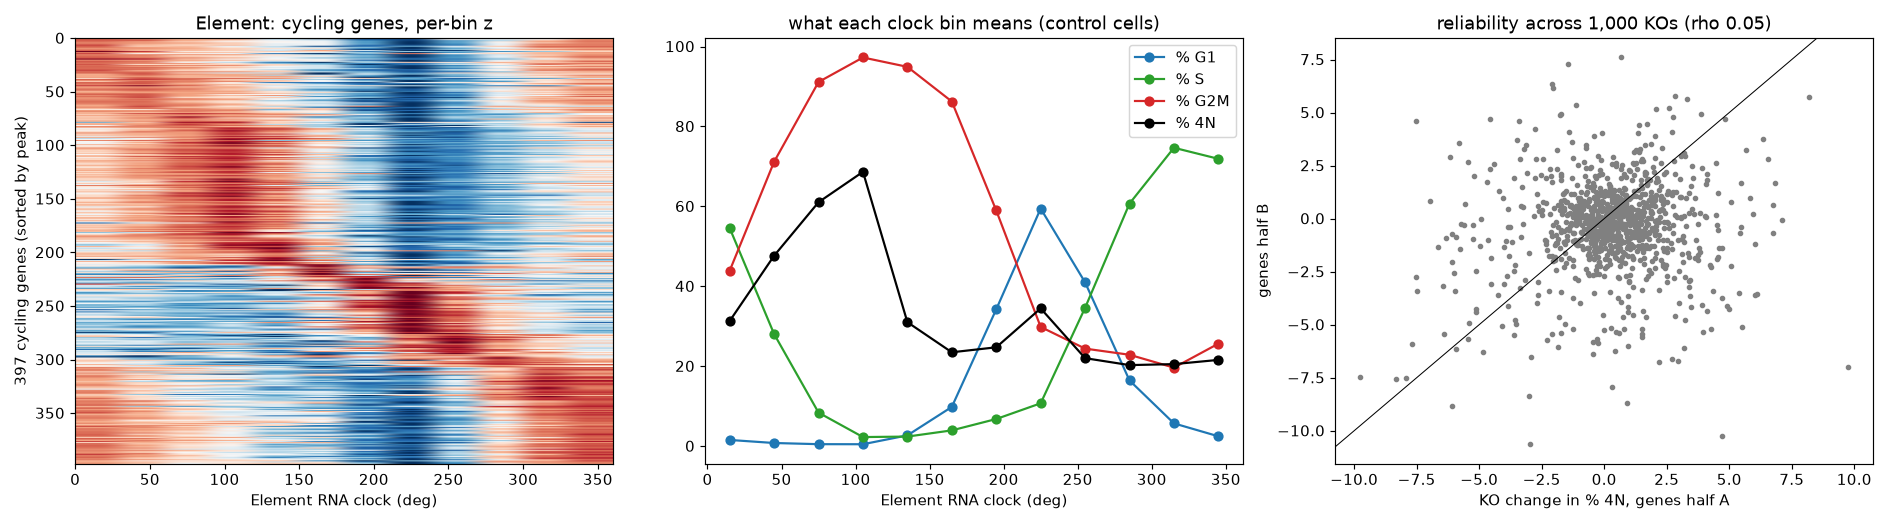

,programme,n_genes,split_half_pearson_all,split_half_spearman_all,n_strong_KOs,split_half_pearson_strong
0,S,131,0.039,-0.020,1,NaN
1,G2M,180,0.225,0.143,4,NaN
2,G1,75,0.162,0.146,10,0.947


,gene,z_S,z_G2M,z_G1
813,SMARCD1,-12.38,-18.47,1.48
891,TIPARP,1.05,2.92,5.52
570,NUP54,-0.40,1.63,4.66
861,SYVN1,0.78,1.17,4.60
372,HAUS4,-2.30,-4.47,1.90
362,GTF2A2,3.03,1.59,-4.28
284,ELP2,-0.34,4.26,2.36
806,SLC38A6,0.86,1.76,4.20
867,TARS,1.07,0.97,4.18
532,NAPA,-1.35,-0.14,4.12


In [9]:
display(Image(filename=find('crop_cycle_overview.png')))
display(pd.read_csv(find('crop_programme_reliability.csv')))
P = pd.read_csv(find('crop_cycle_programmes.csv'))
P.assign(z_max=P[['z_S', 'z_G2M', 'z_G1']].abs().max(1)).nlargest(15, 'z_max')[['gene', 'z_S', 'z_G2M', 'z_G1']].round(2)

**Mapping to phase-contrast morphology, two routes.**
* **Route 1, per cell, no RNA used for training.** The NTC-trained morphology model predicts each knockout's change in % 4N cells, which we compare with its RNA programmes.
* **Route 2, gene level.** A ridge regression from the knockout's mean phase profile to its RNA programme scores, 10-fold cross-validated across knockouts, against permuted labels.
* **Strength control.** Essential-gene knockouts move every readout, so agreement is also given after partialling out overall perturbation strength in each modality.

**Result: phase contrast and CROP-seq agree only weakly on the cell cycle.**
* **Route 1:** RNA G2/M programme vs morphology-predicted change in % 4N gives rho 0.11 (p 7e-4; 0.12 after the strength control).
* **Route 2:** cross-validated rho is 0.10 to 0.16 for the G2/M, G1 and proliferation scores, above the permuted 95th percentile
  (at most 0.03), but R2 is at most 0.09. The S programme is not predicted at all (rho -0.10).
* **The two modalities disagree on which knockouts change the cycle.** None of the 14 strongest RNA knockouts is significant in
  morphology, and the strongest morphology knockouts (RRM1, CDC45, POLR1B, ribosomal genes) show no RNA programme shift.

**Possible reasons** (not tested here): the two screens are different experiments (cells, time point, selection); knockout-level
pseudobulk dilutes a shift carried by part of the cells; and CROP-seq self-knockdown was weak for several targets. **For cell-cycle
readouts of these knockouts, the imaging data (phase contrast, validated against 4i pRb and DNA) are the stronger source.**

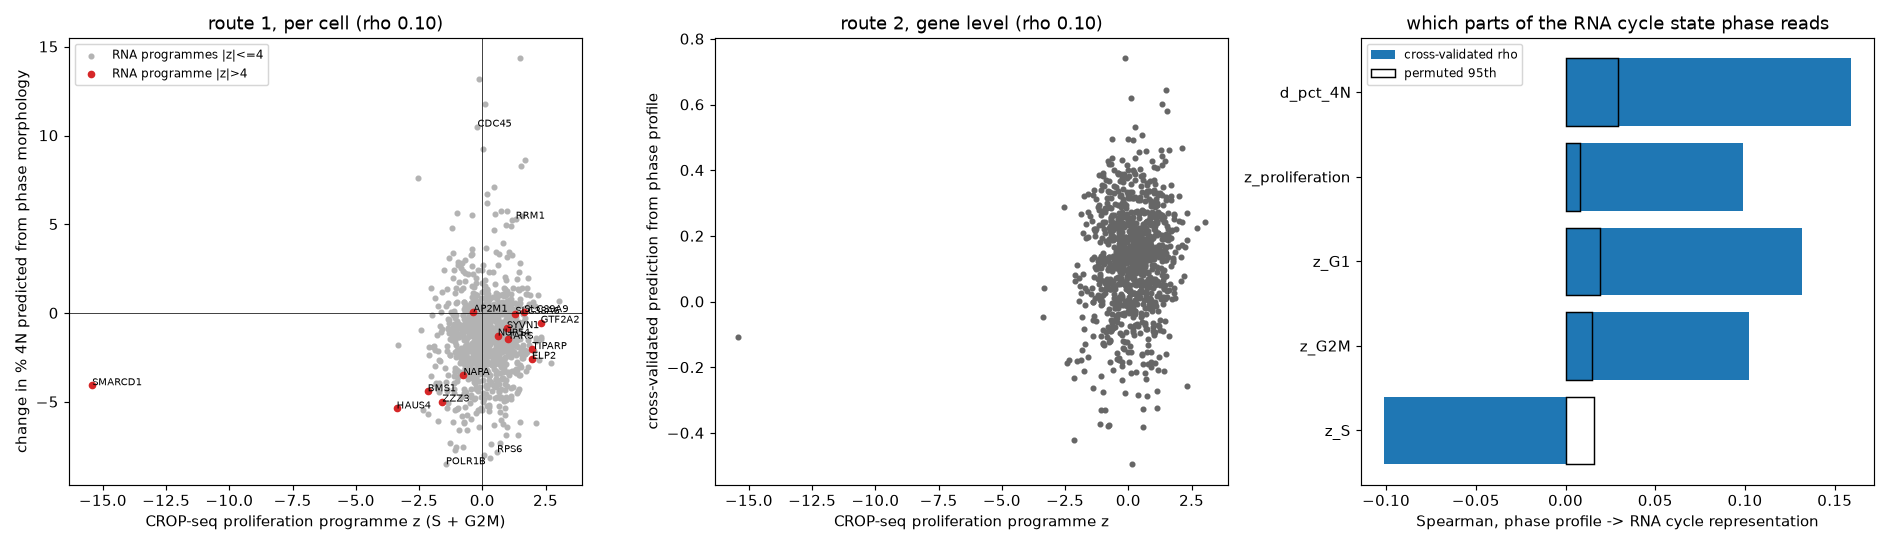

,comparison,n,spearman,p,partial_spearman_given_strength,fraction
0,RNA G2M programme z vs morphology-predicted ...,997,0.108,0.00066,0.124,NaN
1,RNA proliferation z (S+G2M) vs morphology-pr...,997,0.096,0.00230,0.115,NaN
2,RNA G1 programme z vs morphology-predicted d%4N,997,-0.038,0.23000,-0.011,NaN
3,RNA strongest programme |z| vs morphology cy...,997,0.014,0.66000,-0.038,NaN
4,RNA proliferation z vs measured pRb (4i),997,0.074,0.01900,0.099,NaN
5,RNA composition deconvolution d%4N (secondary)...,997,0.057,0.07300,0.067,NaN
6,KOs with a strong RNA programme shift (|z|>4):...,14,NaN,NaN,NaN,0.000
7,"same, all other KOs",983,NaN,NaN,NaN,0.083


,target,n,cv_R2,cv_spearman,null_95th,partial_spearman_given_strength
0,z_S,997,-0.004,-0.101,0.016,-0.127
1,z_G2M,997,0.022,0.102,0.015,0.105
2,z_G1,997,0.013,0.132,0.019,0.130
3,z_proliferation,997,0.018,0.099,0.008,0.096
4,d_pct_4N,997,0.091,0.159,0.029,0.140


In [10]:
display(Image(filename=find('crop_to_phase_overview.png')))
display(pd.read_csv(find('route1_per_cell_agreement.csv')))
pd.read_csv(find('route2_gene_level_cv.csv'))

## Takeaways

1. **Fair comparisons change the knockout story.** With all NTC cells as an out-of-fold reference and a guide-pooled null, CDK7 and
   CCNB1 shift by about +3 to +4 points (not significant), not +7 to +11. Across the library, 81 of 1,000 knockouts change the
   predicted cycle distribution, with sensible biology (replication and mitosis genes gain 4N cells; ribosome, translation and
   chaperonin genes lose them), validated by measured pRb (rho 0.37).
2. **Regressing the cell cycle out does not reduce the heterogeneity of perturbed populations in a meaningful way.** Spread falls by
   about 3% and separation from NTC is unchanged (595 vs 610 knockouts), because the cycle explains only 3 to 6% of phase-morphology
   variance even when measured. Per-knockout AUC changes are not reproducible between runs, so only the aggregate is interpretable.
3. **Normalising by the cycle does not remove field or well effects** (no change with a measured clock). Doing it with a
   morphology-predicted cycle looks helpful only because the predictor absorbs technical differences.
4. **The cycle-mix vs matched-cycle decomposition is the useful output.** It finds perturbations that change the cycle distribution
   and shows that, in both OPS0077 and Element, morphology changes happen at a matched cycle state; none of 1,000 knockouts acts only through the cycle mix.
5. **CROP-seq knockout-level RNA carries little cell-cycle signal** that agrees with imaging (rho about 0.1). The Element single-cell
   data remain the only place where RNA and imaging cell-cycle state are measured in the same cells.